# FieldVision — Stage 5
## UAV-Agent, Queue-Based Shared Network/Compute Simulator

**Goal:** validate the new NOMS system mechanics before training MAPPO.

This notebook uses the Stage 4 workload trace and implements:

- UAVs as decision-making agents;
- one workload queue per UAV;
- top-\(K\) candidate task selection;
- `local / edge / cloud / defer` decisions;
- low / normal / high network service tiers;
- shared wireless bandwidth;
- multi-step in-flight transfers;
- shared edge/cloud compute queues;
- per-UAV local compute;
- deadlines and SLA outcomes;
- simple non-RL policies for debugging and comparison.

**No reinforcement learning is trained here.**

### Important development assumptions

We still have only one measured compute device from Stage 3. Therefore, temporary **development-only compute multipliers** are used to exercise the local/edge/cloud paths.

They are clearly separated from empirical measurements and **must not be reported as real UAV/edge/cloud measurements**. Later, rerun Stage 3 on actual UAV/edge/cloud hardware and replace these multipliers.

## 0. Imports and project paths

In [1]:
from pathlib import Path
from dataclasses import dataclass, field
from collections import defaultdict
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HOME = Path.home()
PROJECT_ROOT = HOME / "Downloads" / "NOMS_Fieldvision"
SIM_DIR = PROJECT_ROOT / "simulator_inputs"
RESULTS_DIR = PROJECT_ROOT / "stage5_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TRACE_PATH = SIM_DIR / "fieldvision_task_trace.csv"
CONFIG_PATH = SIM_DIR / "fieldvision_stage4_config.json"

if not TRACE_PATH.exists():
    raise FileNotFoundError(
        f"{TRACE_PATH} not found. Run Stage 4 first."
    )

trace_df = pd.read_csv(TRACE_PATH)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    stage4_config = json.load(f)

print("Tasks available:", len(trace_df))
print("Configured UAVs:", stage4_config["n_uavs"])
display(trace_df.head())

Tasks available: 5000
Configured UAVs: 4


,task_id,arrival_time_s,uav_id,workload,service_class,priority_weight,experimental_deadline_s,input_size_mb,megapixels,measured_decode_ms,measured_preprocess_ms,measured_compute_ms_current_host,measured_output_kb,compute_profile_device,compute_profile_model,source_dataset,reference_upload_s_at_25mbps,reference_completion_s,compute_demand_normalized,network_demand_normalized
0,task_000000,2.404209,1,Leafy context classification,delay_tolerant,1,6.697156,4.000870,1.048576,5.536792,3.498250,50.117792,3.90625,cpu,MobileNetV3-Small,LeafySpurge,1.280278,1.339431,0.480804,1.000000
1,task_000001,4.740398,2,Leafy orthomosaic tiled analysis,critical,3,17.477765,34.676382,16.777216,75.166375,8.579459,2802.024183,15.62500,cpu,MobileNetV3-Small tiled proxy,LeafySpurge,11.096442,13.982212,26.881185,8.667211
2,task_000002,7.125159,2,Leafy orthomosaic tiled analysis,delay_tolerant,1,54.395912,25.624428,16.777216,328.896334,7.505665,2342.963567,15.62500,cpu,MobileNetV3-Small tiled proxy,LeafySpurge,8.199817,10.879182,22.477193,6.404714
3,task_000003,7.404954,3,Leafy crop classification,standard,2,0.102975,0.006172,0.001521,1.633709,1.045125,46.833334,3.90625,cpu,MobileNetV3-Small,LeafySpurge,0.001975,0.051487,0.449295,0.001543
4,task_000004,7.491391,1,Leafy crop classification,critical,3,0.065461,0.006172,0.001521,1.795750,0.873667,47.724042,3.90625,cpu,MobileNetV3-Small,LeafySpurge,0.001975,0.052369,0.457840,0.001543


## 1. Stage 5 development configuration

These values are for **simulator validation**, not final experiments.

The most important temporary assumptions are the compute multipliers:

- local = slower than the Stage 3 host;
- edge = somewhat faster;
- cloud = faster compute but larger fixed network delay.

They exist only so all execution paths can be tested now.

In [2]:
DEV = {
    # Simulation
    "dt_s": 0.02,
    "arrival_horizon_s": 180.0,
    "drain_s": 90.0,
    "top_k_tasks": 3,

    # Temporary compute-tier assumptions.
    # Replace with measured hardware profiles later.
    "compute_multiplier": {
        "local": 2.0,
        "edge": 0.75,
        "cloud": 0.50,
    },

    # Shared compute capacity
    "edge_slots": 2,
    "cloud_slots": 4,

    # Fixed post-upload / infrastructure delay.
    # Development assumption only.
    "fixed_remote_delay_s": {
        "edge": 0.020,
        "cloud": 0.080,
    },

    # Weighted wireless scheduling.
    "network_tier_weight": {
        "low": 1.0,
        "normal": 2.0,
        "high": 4.0,
    },

    # Development-only network model.
    "network": {
        "seed": 123,
        "initial_mbps": 25.0,
        "min_mbps": 3.0,
        "max_mbps": 50.0,
        "update_interval_s": 1.0,
        "lognormal_sigma": 0.25,
        "outage_probability_per_update": 0.01,
        "outage_min_s": 1.0,
        "outage_max_s": 3.0,
        "outage_capacity_mbps": 0.2,
    },
}

print(json.dumps(DEV, indent=2))

{
  "dt_s": 0.02,
  "arrival_horizon_s": 180.0,
  "drain_s": 90.0,
  "top_k_tasks": 3,
  "compute_multiplier": {
    "local": 2.0,
    "edge": 0.75,
    "cloud": 0.5
  },
  "edge_slots": 2,
  "cloud_slots": 4,
  "fixed_remote_delay_s": {
    "edge": 0.02,
    "cloud": 0.08
  },
  "network_tier_weight": {
    "low": 1.0,
    "normal": 2.0,
    "high": 4.0
  },
  "network": {
    "seed": 123,
    "initial_mbps": 25.0,
    "min_mbps": 3.0,
    "max_mbps": 50.0,
    "update_interval_s": 1.0,
    "lognormal_sigma": 0.25,
    "outage_probability_per_update": 0.01,
    "outage_min_s": 1.0,
    "outage_max_s": 3.0,
    "outage_capacity_mbps": 0.2
  }
}


## 2. Development network model

This is **not** the final NOMS wireless model.

It is a reproducible random-walk capacity process with occasional short outages, used only to validate shared-transfer mechanics.

Later, this class can be replaced by a trace-driven provider without changing the rest of the simulator.

In [3]:
class DevelopmentNetworkModel:
    def __init__(self, cfg):
        self.cfg = cfg
        self.rng = np.random.default_rng(cfg["seed"])
        self.current_mbps = float(cfg["initial_mbps"])
        self.next_update_s = 0.0
        self.outage_until_s = -1.0

    def capacity_mbps(self, now_s):
        if now_s < self.outage_until_s:
            return float(self.cfg["outage_capacity_mbps"])

        if now_s >= self.next_update_s:
            self.next_update_s = now_s + self.cfg["update_interval_s"]

            if self.rng.random() < self.cfg["outage_probability_per_update"]:
                duration = self.rng.uniform(
                    self.cfg["outage_min_s"],
                    self.cfg["outage_max_s"]
                )
                self.outage_until_s = now_s + duration
                return float(self.cfg["outage_capacity_mbps"])

            factor = self.rng.lognormal(
                mean=0.0,
                sigma=self.cfg["lognormal_sigma"]
            )

            # Smooth the random change so capacity does not jump wildly.
            proposed = 0.70 * self.current_mbps + 0.30 * (
                self.cfg["initial_mbps"] * factor
            )

            self.current_mbps = float(np.clip(
                proposed,
                self.cfg["min_mbps"],
                self.cfg["max_mbps"]
            ))

        return self.current_mbps

## 3. Stage 5 simulator

In [4]:
class FieldVisionStage5Sim:
    """
    Queue-based multi-UAV systems simulator.

    UAVs are the decision agents.
    Edge/cloud are shared infrastructure resources.
    """

    def __init__(
        self,
        full_trace_df,
        n_uavs,
        dev_cfg,
        policy_seed=7,
    ):
        self.cfg = dev_cfg
        self.dt = float(dev_cfg["dt_s"])
        self.n_uavs = int(n_uavs)
        self.policy_rng = np.random.default_rng(policy_seed)

        # Only tasks arriving during the experimental horizon are injected.
        horizon = dev_cfg["arrival_horizon_s"]

        self.trace = (
            full_trace_df[
                full_trace_df["arrival_time_s"] < horizon
            ]
            .sort_values("arrival_time_s")
            .reset_index(drop=True)
            .copy()
        )

        self.end_time_s = (
            dev_cfg["arrival_horizon_s"]
            + dev_cfg["drain_s"]
        )

        self.network = DevelopmentNetworkModel(
            dev_cfg["network"]
        )

        self.reset()

    def reset(self):
        self.now_s = 0.0
        self.arrival_idx = 0

        self.tasks = {}
        self.waiting = {
            uav: []
            for uav in range(self.n_uavs)
        }

        # One local processor slot per UAV.
        self.local_active = {
            uav: None
            for uav in range(self.n_uavs)
        }

        # One outbound transfer at a time per UAV.
        self.transfers = {}

        self.edge_queue = []
        self.cloud_queue = []

        self.edge_active = []
        self.cloud_active = []

        self.completed_task_ids = []

        # Resource accounting.
        self.total_network_capacity_mb = 0.0
        self.total_network_transferred_mb = 0.0
        self.edge_busy_slot_seconds = 0.0
        self.cloud_busy_slot_seconds = 0.0
        self.local_busy_slot_seconds = 0.0

        self.system_log = []

        # Use a fresh deterministic network process for each reset.
        self.network = DevelopmentNetworkModel(
            self.cfg["network"]
        )

    # -------------------------------------------------------
    # Task helpers
    # -------------------------------------------------------

    def _task_processing_time_s(self, task, target):
        base_s = (
            float(task["measured_decode_ms"])
            + float(task["measured_preprocess_ms"])
            + float(task["measured_compute_ms_current_host"])
        ) / 1000.0

        return (
            base_s
            * self.cfg["compute_multiplier"][target]
        )

    def _absolute_deadline(self, task):
        return (
            float(task["arrival_time_s"])
            + float(task["experimental_deadline_s"])
        )

    def _inject_arrivals(self):
        while self.arrival_idx < len(self.trace):
            row = self.trace.iloc[self.arrival_idx]

            if float(row["arrival_time_s"]) > self.now_s + 1e-12:
                break

            task = row.to_dict()

            task_id = str(task["task_id"])
            uav = int(task["uav_id"])

            task["absolute_deadline_s"] = self._absolute_deadline(task)
            task["status"] = "waiting"
            task["selected_target"] = None
            task["network_tier"] = None
            task["service_start_s"] = None
            task["compute_start_s"] = None
            task["completion_time_s"] = None
            task["deadline_missed"] = False

            self.tasks[task_id] = task
            self.waiting[uav].append(task_id)

            self.arrival_idx += 1

    def waiting_candidates(self, uav_id, top_k=None):
        if top_k is None:
            top_k = self.cfg["top_k_tasks"]

        ids = list(self.waiting[uav_id])

        # Candidate interface: earliest absolute deadlines first.
        ids.sort(
            key=lambda tid: (
                self.tasks[tid]["absolute_deadline_s"],
                -float(self.tasks[tid]["priority_weight"])
            )
        )

        return [
            self.tasks[tid]
            for tid in ids[:top_k]
        ]

    def uav_has_active_transfer(self, uav_id):
        return any(
            tr["uav_id"] == uav_id
            for tr in self.transfers.values()
        )

    def current_network_mbps(self):
        return self.network.capacity_mbps(self.now_s)

    # -------------------------------------------------------
    # Approximate predictions for heuristic policies only
    # -------------------------------------------------------

    def estimated_completion_from_now_s(self, task, target):
        process_s = self._task_processing_time_s(task, target)

        if target == "local":
            if self.local_active[int(task["uav_id"])] is not None:
                return np.inf
            return process_s

        if self.uav_has_active_transfer(int(task["uav_id"])):
            return np.inf

        bw = max(self.current_network_mbps(), 1e-6)
        upload_s = float(task["input_size_mb"]) * 8.0 / bw

        if target == "edge":
            queue_jobs = len(self.edge_queue) + len(self.edge_active)
            queue_penalty = (
                queue_jobs
                / max(self.cfg["edge_slots"], 1)
            ) * process_s

        elif target == "cloud":
            queue_jobs = len(self.cloud_queue) + len(self.cloud_active)
            queue_penalty = (
                queue_jobs
                / max(self.cfg["cloud_slots"], 1)
            ) * process_s

        else:
            return np.inf

        return (
            upload_s
            + self.cfg["fixed_remote_delay_s"][target]
            + queue_penalty
            + process_s
        )

    # -------------------------------------------------------
    # Action application
    # -------------------------------------------------------

    def apply_actions(self, actions):
        """
        actions:
        {
            uav_id: {
                "task_id": "...",
                "target": "local|edge|cloud|defer",
                "network_tier": "low|normal|high"
            }
        }
        """

        for uav_id, action in actions.items():
            if action is None:
                continue

            target = action.get("target", "defer")

            if target == "defer":
                continue

            task_id = action.get("task_id")

            if task_id not in self.waiting[uav_id]:
                continue

            task = self.tasks[task_id]

            if target == "local":
                if self.local_active[uav_id] is not None:
                    continue

                self.waiting[uav_id].remove(task_id)

                task["status"] = "running_local"
                task["selected_target"] = "local"
                task["service_start_s"] = self.now_s
                task["compute_start_s"] = self.now_s

                self.local_active[uav_id] = {
                    "task_id": task_id,
                    "remaining_s": self._task_processing_time_s(
                        task, "local"
                    )
                }

            elif target in {"edge", "cloud"}:
                if self.uav_has_active_transfer(uav_id):
                    continue

                tier = action.get("network_tier", "normal")

                if tier not in self.cfg["network_tier_weight"]:
                    tier = "normal"

                self.waiting[uav_id].remove(task_id)

                task["status"] = "transmitting"
                task["selected_target"] = target
                task["network_tier"] = tier
                task["service_start_s"] = self.now_s

                self.transfers[task_id] = {
                    "task_id": task_id,
                    "uav_id": uav_id,
                    "target": target,
                    "network_tier": tier,
                    "weight": float(
                        self.cfg["network_tier_weight"][tier]
                    ),
                    "remaining_mb": float(task["input_size_mb"]),
                    "ready_time_s": None,
                }

    # -------------------------------------------------------
    # Shared network
    # -------------------------------------------------------

    def _advance_network(self):
        capacity_mbps = self.current_network_mbps()
        capacity_mb_this_step = (
            capacity_mbps * self.dt / 8.0
        )

        self.total_network_capacity_mb += capacity_mb_this_step

        if not self.transfers:
            return

        total_weight = sum(
            tr["weight"]
            for tr in self.transfers.values()
        )

        finished = []

        for task_id, tr in list(self.transfers.items()):
            share_mbps = (
                capacity_mbps
                * tr["weight"]
                / total_weight
            )

            possible_mb = (
                share_mbps * self.dt / 8.0
            )

            actual_mb = min(
                possible_mb,
                tr["remaining_mb"]
            )

            tr["remaining_mb"] -= actual_mb
            self.total_network_transferred_mb += actual_mb

            if tr["remaining_mb"] <= 1e-12:
                finished.append(task_id)

        for task_id in finished:
            tr = self.transfers.pop(task_id)
            task = self.tasks[task_id]

            target = tr["target"]

            task["status"] = f"queued_{target}"
            task["remote_ready_time_s"] = (
                self.now_s
                + self.cfg["fixed_remote_delay_s"][target]
            )

            if target == "edge":
                self.edge_queue.append(task_id)
            else:
                self.cloud_queue.append(task_id)

    # -------------------------------------------------------
    # Shared compute
    # -------------------------------------------------------

    def _sorted_ready_queue(self, queue_ids):
        ready = [
            tid for tid in queue_ids
            if float(
                self.tasks[tid].get(
                    "remote_ready_time_s",
                    0.0
                )
            ) <= self.now_s
        ]

        ready.sort(
            key=lambda tid: (
                -float(self.tasks[tid]["priority_weight"]),
                float(self.tasks[tid]["absolute_deadline_s"])
            )
        )

        return ready

    def _start_remote_jobs(
        self,
        queue_ids,
        active_jobs,
        slots,
        target,
    ):
        free_slots = slots - len(active_jobs)

        if free_slots <= 0:
            return

        ready = self._sorted_ready_queue(queue_ids)

        for task_id in ready[:free_slots]:
            queue_ids.remove(task_id)

            task = self.tasks[task_id]
            task["status"] = f"running_{target}"
            task["compute_start_s"] = self.now_s

            active_jobs.append({
                "task_id": task_id,
                "remaining_s": self._task_processing_time_s(
                    task, target
                )
            })

    def _complete_task(self, task_id, completion_time_s):
        task = self.tasks[task_id]

        task["status"] = "completed"
        task["completion_time_s"] = completion_time_s

        if completion_time_s > task["absolute_deadline_s"]:
            task["deadline_missed"] = True

        self.completed_task_ids.append(task_id)

    def _advance_compute(self):
        # Start queued remote tasks first.
        self._start_remote_jobs(
            self.edge_queue,
            self.edge_active,
            self.cfg["edge_slots"],
            "edge"
        )

        self._start_remote_jobs(
            self.cloud_queue,
            self.cloud_active,
            self.cfg["cloud_slots"],
            "cloud"
        )

        # Utilization accounting.
        self.edge_busy_slot_seconds += (
            len(self.edge_active) * self.dt
        )
        self.cloud_busy_slot_seconds += (
            len(self.cloud_active) * self.dt
        )
        self.local_busy_slot_seconds += (
            sum(
                job is not None
                for job in self.local_active.values()
            )
            * self.dt
        )

        completion_time = self.now_s + self.dt

        # Local jobs
        for uav_id, job in list(self.local_active.items()):
            if job is None:
                continue

            job["remaining_s"] -= self.dt

            if job["remaining_s"] <= 1e-12:
                self._complete_task(
                    job["task_id"],
                    completion_time
                )
                self.local_active[uav_id] = None

        # Edge jobs
        remaining_edge = []
        for job in self.edge_active:
            job["remaining_s"] -= self.dt

            if job["remaining_s"] <= 1e-12:
                self._complete_task(
                    job["task_id"],
                    completion_time
                )
            else:
                remaining_edge.append(job)

        self.edge_active = remaining_edge

        # Cloud jobs
        remaining_cloud = []
        for job in self.cloud_active:
            job["remaining_s"] -= self.dt

            if job["remaining_s"] <= 1e-12:
                self._complete_task(
                    job["task_id"],
                    completion_time
                )
            else:
                remaining_cloud.append(job)

        self.cloud_active = remaining_cloud

    # -------------------------------------------------------
    # Deadlines / logging
    # -------------------------------------------------------

    def _update_deadline_flags(self):
        next_time = self.now_s + self.dt

        for task in self.tasks.values():
            if task["status"] == "completed":
                continue

            if next_time > task["absolute_deadline_s"]:
                task["deadline_missed"] = True

    def _log_state(self):
        # Log roughly once per second.
        step_idx = int(round(self.now_s / self.dt))
        every = max(1, int(round(1.0 / self.dt)))

        if step_idx % every != 0:
            return

        self.system_log.append({
            "time_s": self.now_s,
            "network_capacity_mbps": self.current_network_mbps(),
            "active_transfers": len(self.transfers),
            "edge_queue": len(self.edge_queue),
            "edge_active": len(self.edge_active),
            "cloud_queue": len(self.cloud_queue),
            "cloud_active": len(self.cloud_active),
            "waiting_total": sum(
                len(q) for q in self.waiting.values()
            ),
            "completed": len(self.completed_task_ids),
        })

    # -------------------------------------------------------
    # Public step / results
    # -------------------------------------------------------

    def step(self, policy_fn):
        self._inject_arrivals()

        actions = policy_fn(self)
        self.apply_actions(actions)

        self._advance_network()
        self._advance_compute()
        self._update_deadline_flags()
        self._log_state()

        self.now_s += self.dt

    def run(self, policy_fn):
        while self.now_s < self.end_time_s:
            self.step(policy_fn)

        return self.metrics()

    def task_results_dataframe(self):
        rows = []

        for task_id, task in self.tasks.items():
            completion = task["completion_time_s"]

            latency = (
                completion - float(task["arrival_time_s"])
                if completion is not None
                else np.nan
            )

            sla_success = (
                completion is not None
                and completion <= task["absolute_deadline_s"]
            )

            rows.append({
                "task_id": task_id,
                "uav_id": int(task["uav_id"]),
                "workload": task["workload"],
                "service_class": task["service_class"],
                "priority_weight": task["priority_weight"],
                "arrival_time_s": task["arrival_time_s"],
                "deadline_s": task["absolute_deadline_s"],
                "target": task["selected_target"],
                "network_tier": task["network_tier"],
                "status": task["status"],
                "completion_time_s": completion,
                "latency_s": latency,
                "sla_success": bool(sla_success),
                "deadline_missed": bool(task["deadline_missed"]),
                "input_size_mb": task["input_size_mb"],
            })

        return pd.DataFrame(rows)

    def metrics(self):
        df = self.task_results_dataframe()

        n = len(df)
        completed = df["completion_time_s"].notna()

        completed_df = df[completed].copy()

        if len(completed_df):
            p50 = completed_df["latency_s"].median()
            p95 = np.percentile(
                completed_df["latency_s"],
                95
            )
        else:
            p50 = np.nan
            p95 = np.nan

        per_uav = (
            df.groupby("uav_id")["sla_success"]
            .mean()
            .reindex(range(self.n_uavs), fill_value=0.0)
            .to_numpy(dtype=float)
        )

        denom = (
            len(per_uav)
            * np.sum(per_uav ** 2)
        )

        jain = (
            (np.sum(per_uav) ** 2) / denom
            if denom > 0
            else 0.0
        )

        total_sim_s = self.end_time_s

        network_util = (
            self.total_network_transferred_mb
            / self.total_network_capacity_mb
            if self.total_network_capacity_mb > 0
            else 0.0
        )

        edge_util = (
            self.edge_busy_slot_seconds
            / (
                self.cfg["edge_slots"]
                * total_sim_s
            )
        )

        cloud_util = (
            self.cloud_busy_slot_seconds
            / (
                self.cfg["cloud_slots"]
                * total_sim_s
            )
        )

        local_util = (
            self.local_busy_slot_seconds
            / (
                self.n_uavs
                * total_sim_s
            )
        )

        return {
            "tasks": n,
            "completed": int(completed.sum()),
            "completion_rate": float(completed.mean()),
            "sla_success_rate": float(df["sla_success"].mean()),
            "deadline_violation_rate": float(
                1.0 - df["sla_success"].mean()
            ),
            "latency_p50_s": float(p50),
            "latency_p95_s": float(p95),
            "network_utilization": float(network_util),
            "local_compute_utilization": float(local_util),
            "edge_compute_utilization": float(edge_util),
            "cloud_compute_utilization": float(cloud_util),
            "uav_sla_jain_fairness": float(jain),
        }

## 4. Simple debugging policies

These are not proposed algorithms. Their purpose is to verify the simulator and later serve as simple baselines.

- `local_only`: earliest-deadline task, local execution only.
- `edf_min_completion`: earliest-deadline task, then estimates the fastest feasible target.
- `priority_aware`: highest service priority first, then earliest deadline, then fastest feasible target.
- `random_policy`: exercises all routes and is useful for debugging.

In [5]:
def network_tier_for_task(task):
    service_class = task["service_class"]

    if service_class == "critical":
        return "high"

    if service_class == "delay_tolerant":
        return "low"

    return "normal"


def local_only_policy(env):
    actions = {}

    for uav in range(env.n_uavs):
        candidates = env.waiting_candidates(uav)

        if not candidates:
            continue

        if env.local_active[uav] is not None:
            continue

        task = candidates[0]

        actions[uav] = {
            "task_id": task["task_id"],
            "target": "local",
            "network_tier": "normal",
        }

    return actions


def choose_fastest_target(env, task):
    targets = ["local", "edge", "cloud"]

    estimates = {
        target: env.estimated_completion_from_now_s(
            task, target
        )
        for target in targets
    }

    return min(
        estimates,
        key=estimates.get
    )


def edf_min_completion_policy(env):
    actions = {}

    for uav in range(env.n_uavs):
        candidates = env.waiting_candidates(uav)

        if not candidates:
            continue

        task = min(
            candidates,
            key=lambda t: t["absolute_deadline_s"]
        )

        target = choose_fastest_target(
            env, task
        )

        if not np.isfinite(
            env.estimated_completion_from_now_s(
                task, target
            )
        ):
            continue

        actions[uav] = {
            "task_id": task["task_id"],
            "target": target,
            "network_tier": network_tier_for_task(task),
        }

    return actions


def priority_aware_policy(env):
    actions = {}

    for uav in range(env.n_uavs):
        candidates = env.waiting_candidates(uav)

        if not candidates:
            continue

        task = sorted(
            candidates,
            key=lambda t: (
                -float(t["priority_weight"]),
                float(t["absolute_deadline_s"])
            )
        )[0]

        target = choose_fastest_target(
            env, task
        )

        if not np.isfinite(
            env.estimated_completion_from_now_s(
                task, target
            )
        ):
            continue

        actions[uav] = {
            "task_id": task["task_id"],
            "target": target,
            "network_tier": network_tier_for_task(task),
        }

    return actions


def random_policy(env):
    actions = {}

    for uav in range(env.n_uavs):
        candidates = env.waiting_candidates(uav)

        if not candidates:
            continue

        task = candidates[
            env.policy_rng.integers(
                0,
                len(candidates)
            )
        ]

        feasible_targets = []

        if env.local_active[uav] is None:
            feasible_targets.append("local")

        if not env.uav_has_active_transfer(uav):
            feasible_targets.extend(
                ["edge", "cloud"]
            )

        # Sometimes intentionally defer.
        if env.policy_rng.random() < 0.10:
            actions[uav] = {
                "task_id": task["task_id"],
                "target": "defer",
                "network_tier": "normal",
            }
            continue

        if not feasible_targets:
            continue

        target = env.policy_rng.choice(
            feasible_targets
        )

        tier = env.policy_rng.choice(
            ["low", "normal", "high"]
        )

        actions[uav] = {
            "task_id": task["task_id"],
            "target": str(target),
            "network_tier": str(tier),
        }

    return actions

## 5. Smoke test one policy

Run this before the full comparison. If this cell completes and prints sensible metrics, the main event loop is working.

In [6]:
smoke_env = FieldVisionStage5Sim(
    trace_df,
    n_uavs=stage4_config["n_uavs"],
    dev_cfg=DEV,
    policy_seed=11,
)

smoke_metrics = smoke_env.run(
    priority_aware_policy
)

print("Smoke-test metrics:")
for k, v in smoke_metrics.items():
    print(f"{k}: {v}")

smoke_results = smoke_env.task_results_dataframe()

print("\nTarget usage:")
display(
    smoke_results.groupby(
        "target",
        dropna=False
    ).size().reset_index(name="tasks")
)

print("\nSLA success by service class:")
display(
    smoke_results.groupby(
        "service_class"
    )["sla_success"].agg(
        ["count", "mean"]
    )
)

Smoke-test metrics:
tasks: 187
completed: 187
completion_rate: 1.0
sla_success_rate: 0.8074866310160428
deadline_violation_rate: 0.1925133689839572
latency_p50_s: 0.41272087585983286
latency_p95_s: 11.783224792764498
network_utilization: 0.5333528039935411
local_compute_utilization: 0.2416851851851881
edge_compute_utilization: 0.00592592592592593
cloud_compute_utilization: 0.024296296296295865
uav_sla_jain_fairness: 0.9984518078754272

Target usage:


,target,tasks
0,cloud,17
1,edge,48
2,local,122



SLA success by service class:


,count,mean
service_class,,
critical,44,0.704545
delay_tolerant,36,0.944444
standard,107,0.803738


## 6. Compare simple policies

This is still a **simulator validation experiment**, not a paper result.

In [7]:
POLICIES = {
    "Local Only": local_only_policy,
    "EDF + Min Completion": edf_min_completion_policy,
    "Priority Aware": priority_aware_policy,
    "Random": random_policy,
}

policy_metrics = []
policy_task_results = {}
policy_logs = {}

for i, (name, policy_fn) in enumerate(POLICIES.items()):
    print("Running:", name)

    env = FieldVisionStage5Sim(
        trace_df,
        n_uavs=stage4_config["n_uavs"],
        dev_cfg=DEV,
        policy_seed=100 + i,
    )

    metrics = env.run(policy_fn)
    metrics["policy"] = name

    policy_metrics.append(metrics)
    policy_task_results[name] = env.task_results_dataframe()
    policy_logs[name] = pd.DataFrame(env.system_log)

metrics_df = pd.DataFrame(policy_metrics)

cols = [
    "policy",
    "tasks",
    "completion_rate",
    "sla_success_rate",
    "latency_p50_s",
    "latency_p95_s",
    "network_utilization",
    "local_compute_utilization",
    "edge_compute_utilization",
    "cloud_compute_utilization",
    "uav_sla_jain_fairness",
]

display(
    metrics_df[cols]
    .sort_values(
        "sla_success_rate",
        ascending=False
    )
)

Running: Local Only
Running: EDF + Min Completion
Running: Priority Aware
Running: Random


,policy,tasks,completion_rate,sla_success_rate,latency_p50_s,latency_p95_s,network_utilization,local_compute_utilization,edge_compute_utilization,cloud_compute_utilization,uav_sla_jain_fairness
1,EDF + Min Completion,187,1.0,0.807487,0.412721,11.783225,0.533353,0.241685,0.005926,0.024296,0.998452
2,Priority Aware,187,1.0,0.807487,0.412721,11.783225,0.533353,0.241685,0.005926,0.024296,0.998452
0,Local Only,187,1.0,0.609626,2.972072,11.061926,0.000000,0.345704,0.000000,0.000000,0.990680
3,Random,187,1.0,0.588235,2.040339,21.392966,0.683188,0.227500,0.060185,0.009889,0.998415


## 7. SLA success by workload

In [8]:
workload_rows = []

for policy_name, df in policy_task_results.items():
    grouped = (
        df.groupby("workload")["sla_success"]
        .agg(["count", "mean"])
        .reset_index()
    )

    grouped["policy"] = policy_name
    workload_rows.append(grouped)

sla_by_workload = pd.concat(
    workload_rows,
    ignore_index=True
)

display(
    sla_by_workload[
        ["policy", "workload", "count", "mean"]
    ].rename(
        columns={"mean": "sla_success_rate"}
    )
)

,policy,workload,count,sla_success_rate
0,Local Only,Leafy context classification,45,0.711111
1,Local Only,Leafy crop classification,46,0.043478
2,Local Only,Leafy orthomosaic tiled analysis,51,0.980392
3,Local Only,Rumex weed detection,45,0.666667
4,EDF + Min Completion,Leafy context classification,45,0.911111
5,EDF + Min Completion,Leafy crop classification,46,0.500000
6,EDF + Min Completion,Leafy orthomosaic tiled analysis,51,0.960784
7,EDF + Min Completion,Rumex weed detection,45,0.844444
8,Priority Aware,Leafy context classification,45,0.911111
9,Priority Aware,Leafy crop classification,46,0.500000


## 8. SLA success by service class

In [9]:
service_rows = []

for policy_name, df in policy_task_results.items():
    grouped = (
        df.groupby("service_class")["sla_success"]
        .agg(["count", "mean"])
        .reset_index()
    )

    grouped["policy"] = policy_name
    service_rows.append(grouped)

sla_by_service = pd.concat(
    service_rows,
    ignore_index=True
)

display(
    sla_by_service[
        ["policy", "service_class", "count", "mean"]
    ].rename(
        columns={"mean": "sla_success_rate"}
    )
)

,policy,service_class,count,sla_success_rate
0,Local Only,critical,44,0.590909
1,Local Only,delay_tolerant,36,0.861111
2,Local Only,standard,107,0.532710
3,EDF + Min Completion,critical,44,0.704545
4,EDF + Min Completion,delay_tolerant,36,0.944444
5,EDF + Min Completion,standard,107,0.803738
6,Priority Aware,critical,44,0.704545
7,Priority Aware,delay_tolerant,36,0.944444
8,Priority Aware,standard,107,0.803738
9,Random,critical,44,0.431818


## 9. Target-selection sanity check

In [10]:
target_rows = []

for policy_name, df in policy_task_results.items():
    grouped = (
        df.groupby(
            "target",
            dropna=False
        )
        .size()
        .reset_index(name="tasks")
    )

    grouped["policy"] = policy_name
    target_rows.append(grouped)

target_usage = pd.concat(
    target_rows,
    ignore_index=True
)

display(target_usage)

,target,tasks,policy
0,local,187,Local Only
1,cloud,17,EDF + Min Completion
2,edge,48,EDF + Min Completion
3,local,122,EDF + Min Completion
4,cloud,17,Priority Aware
5,edge,48,Priority Aware
6,local,122,Priority Aware
7,cloud,25,Random
8,edge,30,Random
9,local,132,Random


## 10. Plot SLA success rate

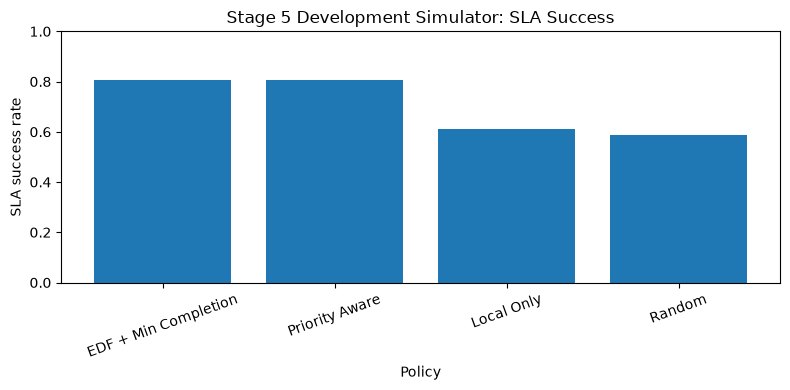

In [11]:
plot_df = (
    metrics_df
    .sort_values("sla_success_rate", ascending=False)
)

plt.figure(figsize=(8, 4))

plt.bar(
    plot_df["policy"],
    plot_df["sla_success_rate"]
)

plt.ylabel("SLA success rate")
plt.xlabel("Policy")
plt.title("Stage 5 Development Simulator: SLA Success")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 11. Inspect shared-network behavior

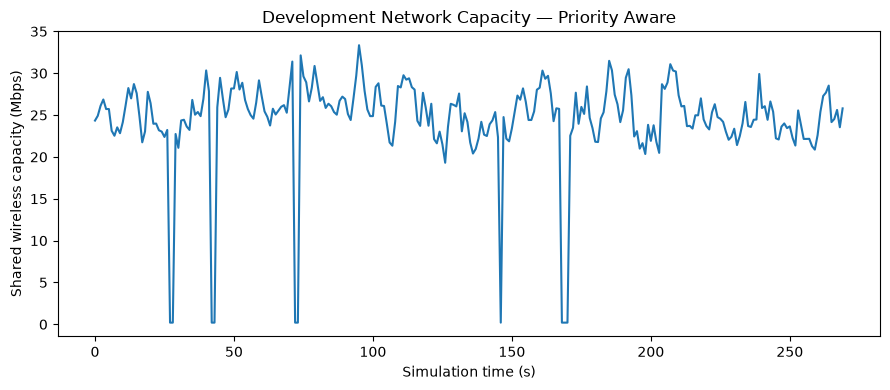

In [12]:
policy_to_plot = "Priority Aware"

log_df = policy_logs[policy_to_plot]

plt.figure(figsize=(9, 4))
plt.plot(
    log_df["time_s"],
    log_df["network_capacity_mbps"]
)
plt.xlabel("Simulation time (s)")
plt.ylabel("Shared wireless capacity (Mbps)")
plt.title(
    f"Development Network Capacity — {policy_to_plot}"
)
plt.tight_layout()
plt.show()

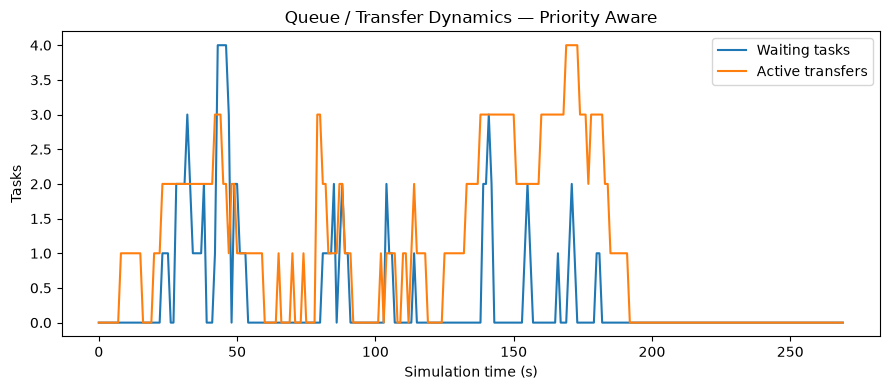

In [13]:
plt.figure(figsize=(9, 4))
plt.plot(
    log_df["time_s"],
    log_df["waiting_total"],
    label="Waiting tasks"
)
plt.plot(
    log_df["time_s"],
    log_df["active_transfers"],
    label="Active transfers"
)
plt.xlabel("Simulation time (s)")
plt.ylabel("Tasks")
plt.title(
    f"Queue / Transfer Dynamics — {policy_to_plot}"
)
plt.legend()
plt.tight_layout()
plt.show()

## 12. Inspect individual task outcomes

This is useful for debugging unexpected misses.

In [14]:
debug_df = policy_task_results[
    "Priority Aware"
].copy()

display(
    debug_df[
        [
            "task_id",
            "uav_id",
            "workload",
            "service_class",
            "target",
            "network_tier",
            "arrival_time_s",
            "deadline_s",
            "completion_time_s",
            "latency_s",
            "sla_success",
        ]
    ].head(30)
)

,task_id,uav_id,workload,service_class,target,network_tier,arrival_time_s,deadline_s,completion_time_s,latency_s,sla_success
0,task_000000,1,Leafy context classification,delay_tolerant,local,NaN,2.404209,9.101364,2.54,0.135791,True
1,task_000001,2,Leafy orthomosaic tiled analysis,critical,local,NaN,4.740398,22.218164,10.54,5.799602,True
2,task_000002,2,Leafy orthomosaic tiled analysis,delay_tolerant,cloud,low,7.125159,61.521072,16.50,9.374841,True
3,task_000003,3,Leafy crop classification,standard,edge,normal,7.404954,7.507928,7.48,0.075046,True
4,task_000004,1,Leafy crop classification,critical,edge,high,7.491391,7.556852,7.56,0.068609,False
5,task_000005,0,Leafy context classification,critical,local,NaN,8.944051,10.616676,9.08,0.135949,True
6,task_000006,3,Rumex weed detection,critical,local,NaN,10.354012,12.702025,10.80,0.445988,True
7,task_000007,3,Leafy context classification,delay_tolerant,local,NaN,13.478308,20.203616,13.62,0.141692,True
8,task_000008,2,Leafy crop classification,standard,local,NaN,13.557602,13.663544,13.68,0.122398,False
9,task_000009,0,Leafy crop classification,critical,edge,high,14.604163,14.680334,14.70,0.095837,False


## 13. Save Stage 5 development outputs

In [15]:
metrics_path = RESULTS_DIR / "stage5_policy_metrics.csv"
workload_path = RESULTS_DIR / "stage5_sla_by_workload.csv"
service_path = RESULTS_DIR / "stage5_sla_by_service_class.csv"
target_path = RESULTS_DIR / "stage5_target_usage.csv"

metrics_df.to_csv(metrics_path, index=False)

sla_by_workload.rename(
    columns={"mean": "sla_success_rate"}
).to_csv(
    workload_path,
    index=False
)

sla_by_service.rename(
    columns={"mean": "sla_success_rate"}
).to_csv(
    service_path,
    index=False
)

target_usage.to_csv(
    target_path,
    index=False
)

for policy_name, df in policy_task_results.items():
    safe = (
        policy_name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )

    df.to_csv(
        RESULTS_DIR
        / f"stage5_tasks_{safe}.csv",
        index=False
    )

print("Saved Stage 5 results to:")
print(RESULTS_DIR)

for p in sorted(RESULTS_DIR.glob("*.csv")):
    print(" -", p.name)

Saved Stage 5 results to:
/Users/bwbgv/Downloads/NOMS_Fieldvision/stage5_results
 - stage5_policy_metrics.csv
 - stage5_sla_by_service_class.csv
 - stage5_sla_by_workload.csv
 - stage5_target_usage.csv
 - stage5_tasks_edf_plus_min_completion.csv
 - stage5_tasks_local_only.csv
 - stage5_tasks_priority_aware.csv
 - stage5_tasks_random.csv


# What to check after running Stage 5

We are **not** looking for the best policy yet.

We are checking whether the system behaves logically:

1. Tasks arrive at the correct UAV queues.
2. Local jobs consume local compute without network transfer.
3. Edge/cloud jobs spend multiple timesteps in transit.
4. Concurrent offloads share the same wireless bottleneck.
5. High network tiers receive larger weighted shares during contention.
6. Edge/cloud jobs queue when compute slots are occupied.
7. Critical/short-deadline jobs can miss their SLA under congestion.
8. Large orthomosaics create substantially more network pressure than tiny crop tasks.
9. The simulator produces per-workload and per-service-class SLA metrics.
10. Different policies generate visibly different routing and queue behavior.

## After Stage 5 is validated

The next steps should be:

**Stage 6A:** replace development compute multipliers with real UAV / edge / cloud profiles.

**Stage 6B:** replace the development network model with real or realistic trace-driven wireless data.

**Stage 7:** wrap the validated simulator as a MARL environment and train the new MAPPO policy.

Only after the simulator is stable should RL be introduced.